## A restaurant company wants to enter the Bengaluru market but does not know which location, restaurant type, cuisine, pricing range, and service options are most suitable. Using Zomato restaurant data, analyze the market to identify restaurant demand patterns, customer preferences, pricing patterns, service adoption, and factors associated with higher ratings and customer engagement.

In [1]:
import pandas as pd
import numpy as np

In [2]:
Restaurant = pd.read_csv(r"C:\Users\Shivaram\Downloads\zomato.csv\zomato.csv")

In [3]:
Restaurant.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   url                          51717 non-null  str  
 1   address                      51717 non-null  str  
 2   name                         51717 non-null  str  
 3   online_order                 51717 non-null  str  
 4   book_table                   51717 non-null  str  
 5   rate                         43942 non-null  str  
 6   votes                        51717 non-null  int64
 7   phone                        50509 non-null  str  
 8   location                     51696 non-null  str  
 9   rest_type                    51490 non-null  str  
 10  dish_liked                   23639 non-null  str  
 11  cuisines                     51672 non-null  str  
 12  approx_cost(for two people)  51371 non-null  str  
 13  reviews_list                 51717 non-null  str  
 14  m

In [4]:
Restaurant.shape

(51717, 17)

In [5]:
# there are 51,717 rows and 17 columns

# Inconsistent data

In [6]:
Restaurant['rate']=Restaurant['rate'].replace('/5','',regex=True)
Restaurant['rate'].unique()

<ArrowStringArray>
[ '4.1',  '3.8',  '3.7',  '3.6',  '4.6',  '4.0',  '4.2',  '3.9',  '3.1',
  '3.0',  '3.2',  '3.3',  '2.8',  '4.4',  '4.3',  'NEW',  '2.9',  '3.5',
    nan,  '2.6', '3.8 ',  '3.4',  '4.5',  '2.5',  '2.7',  '4.7',  '2.4',
  '2.2',  '2.3', '3.4 ',    '-', '3.6 ',  '4.8', '3.9 ', '4.2 ', '4.0 ',
 '4.1 ', '3.7 ', '3.1 ', '2.9 ', '3.3 ', '2.8 ', '3.5 ', '2.7 ', '2.5 ',
 '3.2 ', '2.6 ', '4.5 ', '4.3 ', '4.4 ',  '4.9',  '2.1',  '2.0',  '1.8',
 '4.6 ', '4.9 ', '3.0 ', '4.8 ', '2.3 ', '4.7 ', '2.4 ', '2.1 ', '2.2 ',
 '2.0 ', '1.8 ']
Length: 65, dtype: str

In [7]:
Restaurant['rate'] = Restaurant['rate'].replace(r"^(?!\s*\d+(\.\d+)?\s*$).*$",
    np.nan,
    regex=True)

In [8]:
Restaurant['rate'].unique()

<ArrowStringArray>
[ '4.1',  '3.8',  '3.7',  '3.6',  '4.6',  '4.0',  '4.2',  '3.9',  '3.1',
  '3.0',  '3.2',  '3.3',  '2.8',  '4.4',  '4.3',    nan,  '2.9',  '3.5',
  '2.6', '3.8 ',  '3.4',  '4.5',  '2.5',  '2.7',  '4.7',  '2.4',  '2.2',
  '2.3', '3.4 ', '3.6 ',  '4.8', '3.9 ', '4.2 ', '4.0 ', '4.1 ', '3.7 ',
 '3.1 ', '2.9 ', '3.3 ', '2.8 ', '3.5 ', '2.7 ', '2.5 ', '3.2 ', '2.6 ',
 '4.5 ', '4.3 ', '4.4 ',  '4.9',  '2.1',  '2.0',  '1.8', '4.6 ', '4.9 ',
 '3.0 ', '4.8 ', '2.3 ', '4.7 ', '2.4 ', '2.1 ', '2.2 ', '2.0 ', '1.8 ']
Length: 63, dtype: str

In [9]:
Restaurant['rate']=Restaurant['rate'].astype('float64')

In [10]:
Restaurant['rate'].dtype

dtype('float64')

In [11]:
Restaurant['approx_cost(for two people)']=Restaurant['approx_cost(for two people)'].replace(',','',regex=True)

In [12]:
Restaurant['approx_cost(for two people)'].unique()

<ArrowStringArray>
[ '800',  '300',  '600',  '700',  '550',  '500',  '450',  '650',  '400',
  '900',  '200',  '750',  '150',  '850',  '100', '1200',  '350',  '250',
  '950', '1000', '1500', '1300',  '199',   '80', '1100',  '160', '1600',
  '230',  '130',   '50',  '190', '1700',    nan, '1400',  '180', '1350',
 '2200', '2000', '1800', '1900',  '330', '2500', '2100', '3000', '2800',
 '3400',   '40', '1250', '3500', '4000', '2400', '2600',  '120', '1450',
  '469',   '70', '3200',   '60',  '560',  '240',  '360', '6000', '1050',
 '2300', '4100', '5000', '3700', '1650', '2700', '4500',  '140']
Length: 71, dtype: str

In [13]:
Restaurant['approx_cost(for two people)']=Restaurant['approx_cost(for two people)'].astype('float64')
Restaurant['approx_cost(for two people)'].info()

<class 'pandas.Series'>
RangeIndex: 51717 entries, 0 to 51716
Series name: approx_cost(for two people)
Non-Null Count  Dtype  
--------------  -----  
51371 non-null  float64
dtypes: float64(1)
memory usage: 404.2 KB


# Missing values 

In [14]:
Restaurant.isna().mean()*100

url                             0.000000
address                         0.000000
name                            0.000000
online_order                    0.000000
book_table                      0.000000
rate                           19.436549
votes                           0.000000
phone                           2.335789
location                        0.040606
rest_type                       0.438927
dish_liked                     54.291626
cuisines                        0.087012
approx_cost(for two people)     0.669026
reviews_list                    0.000000
menu_item                       0.000000
listed_in(type)                 0.000000
listed_in(city)                 0.000000
dtype: float64

In [15]:
Normalise = []
for i in Restaurant.isna().sum():
    Normalise.append(i/len(Restaurant)*100)
Normalise

[0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 19.436548910416303,
 0.0,
 2.335789005549432,
 0.04060560357329312,
 0.438927238625597,
 54.29162557766305,
 0.08701200765705668,
 0.669025658874258,
 0.0,
 0.0,
 0.0,
 0.0]

In [16]:
df = pd.DataFrame({'Column_name':Restaurant.columns,'Normalizee':Normalise})

In [17]:
aa = df[df['Normalizee']>0]

In [18]:
for i in aa['Column_name']:
    if Restaurant[i].dtype == 'str':
        Restaurant[i]=Restaurant[i].fillna(Restaurant[i].mode()[0])
    else:
        Restaurant[i]=Restaurant[i].fillna(Restaurant[i].mean())

In [19]:
print(Restaurant.isna().sum())
print(Restaurant.info())

url                            0
address                        0
name                           0
online_order                   0
book_table                     0
rate                           0
votes                          0
phone                          0
location                       0
rest_type                      0
dish_liked                     0
cuisines                       0
approx_cost(for two people)    0
reviews_list                   0
menu_item                      0
listed_in(type)                0
listed_in(city)                0
dtype: int64
<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 17 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          51717 non-null  str    
 1   address                      51717 non-null  str    
 2   name                         51717 non-null  str    
 3   online_order                 5171

# `Mising values are handled `

# Duplicates

In [20]:
Restaurant.duplicated().sum()

np.int64(0)

In [21]:
#Row = Restaurant.T
#Row.duplicated().sum()

# ` #  Duplicates are handled`

# Outliers

In [22]:
for i in Restaurant.columns:
    if Restaurant[i].dtype == 'int64' or Restaurant[i].dtype == 'float64':
        q1 = Restaurant[str(i)].quantile(0.25)
        q3 = Restaurant[str(i)].quantile(0.75)
        iqr = q3-q1
        ub = q3+1.5*iqr
        lb = q1-1.5*iqr
        out = Restaurant[(Restaurant[str(i)]<lb)|(Restaurant[str(i)]>ub)]
        print(i,'outlier = ',len(out))

rate outlier =  2845
votes outlier =  6961
approx_cost(for two people) outlier =  4764


In [23]:
#For rates there will between 0 to 5
for i in Restaurant['rate']:
    if i>5:
        print('Greater then 5')
    elif i<0:
        print('Less then 0 values are present')

In [24]:
from feature_engine.outliers import Winsorizer

In [25]:
Win = Winsorizer(capping_method='iqr',tail='both')

In [26]:
Restaurant = Win.fit_transform(Restaurant)

In [27]:
for i in Restaurant.columns:
    if Restaurant[i].dtype == 'int64' or Restaurant[i].dtype == 'float64':
        q1 = Restaurant[str(i)].quantile(0.25)
        q3 = Restaurant[str(i)].quantile(0.75)
        iqr = q3-q1
        ub = q3+1.5*iqr
        lb = q1-1.5*iqr
        out = Restaurant[(Restaurant[str(i)]<lb)|(Restaurant[str(i)]>ub)]
        print(i,'outlier = ',len(out))

rate outlier =  0
votes outlier =  0
approx_cost(for two people) outlier =  0


# `Outliers Handeled`

# data manipulation

# Price manipulation for high low medium 

In [28]:
def price_category(x):
    if pd.isna(x):
        return np.nan
    elif x < 500:
        return 'Low'
    elif x < 1000:
        return 'Medium'
    else:
        return 'High'



In [29]:
Restaurant['price_category'] = (Restaurant['approx_cost(for two people)'].apply(price_category))

In [30]:
Restaurant['price_category'].unique()

<ArrowStringArray>
['Medium', 'Low', 'High']
Length: 3, dtype: str

# Ratings manipulation of low average and high

In [31]:
def rating_category(x):
    if pd.isna(x):
        return np.nan
    elif x < 3:
        return 'Low'
    elif x < 4:
        return 'Average'
    else:
        return 'High'

In [32]:
Restaurant['rating_category'] = (Restaurant['rate'].apply(rating_category))

In [33]:
Restaurant['rating_category'].unique()

<ArrowStringArray>
['High', 'Average', 'Low']
Length: 3, dtype: str

# As cusins can be more then 2 so we split the cusins

In [34]:
Restaurant_cuisine = Restaurant.assign(cuisine=Restaurant['cuisines'].str.split(', ')).explode('cuisine')

In [35]:
Restaurant_cuisine['cuisine'].value_counts() # t=by this we can have idea of difireent cussins in the different restaurents 

cuisine
North Indian    21130
Chinese         15547
South Indian     8644
Fast Food        8096
Biryani          6492
                ...  
Sindhi              4
Hot dogs            3
Pan Asian           3
Indian              2
Malwani             2
Name: count, Length: 107, dtype: int64

# votes manipulation 

In [36]:
def engagement_category(x):
    if pd.isna(x):
        return np.nan
    elif x < 100:
        return 'Low'
    elif x < 300:
        return 'Medium'
    else:
        return 'High'

In [37]:
Restaurant['engagement_category'] = (
    Restaurant['votes']
    .apply(engagement_category)
)

In [38]:
Restaurant['engagement_category'].unique()

<ArrowStringArray>
['High', 'Low', 'Medium']
Length: 3, dtype: str

In [39]:
def performance_group(row):
    if pd.isna(row['rate']) or pd.isna(row['votes']):
        return np.nan
    if row['rate'] >= 4 and row['votes'] >= 300:
        return 'High Rating & High Engagement'
    elif row['rate'] >= 4:
        return 'High Rating & Low Engagement'
    elif row['votes'] >= 300:
        return 'Low Rating & High Engagement'
    else:
        return 'Low Rating & Low Engagement'

In [40]:
Restaurant['performance_group'] = (
    Restaurant.apply(performance_group, axis=1)
)

In [41]:
Restaurant['performance_group'].unique()

<ArrowStringArray>
['High Rating & High Engagement',  'Low Rating & High Engagement',
   'Low Rating & Low Engagement',  'High Rating & Low Engagement']
Length: 4, dtype: str

# Plots

## Univariate analysis

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt

In [43]:
Restaurant.info()

<class 'pandas.DataFrame'>
RangeIndex: 51717 entries, 0 to 51716
Data columns (total 21 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   url                          51717 non-null  str    
 1   address                      51717 non-null  str    
 2   name                         51717 non-null  str    
 3   online_order                 51717 non-null  str    
 4   book_table                   51717 non-null  str    
 5   rate                         51717 non-null  float64
 6   votes                        51717 non-null  float64
 7   phone                        51717 non-null  str    
 8   location                     51717 non-null  str    
 9   rest_type                    51717 non-null  str    
 10  dish_liked                   51717 non-null  str    
 11  cuisines                     51717 non-null  str    
 12  approx_cost(for two people)  51717 non-null  float64
 13  reviews_list               

In [44]:
def univar(f,v):
    sns.histplot(data=f,x=v)

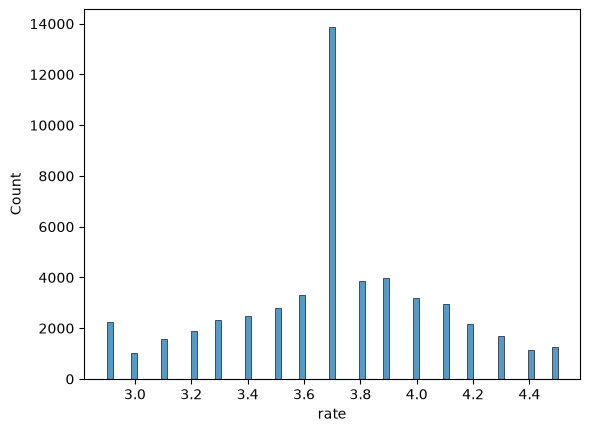

In [45]:
univar(Restaurant,'rate')

Insights = 
+ The ratings are between 3.5 and 4.0
+ The rating 3.7 has the highest frequency
+ below 3.2 and above 4.2 occur less frequently.

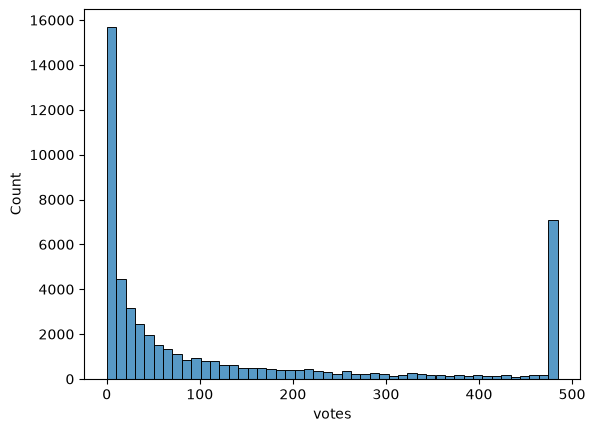

In [46]:
univar(Restaurant,'votes')

insights = 
+ A very large number of restaurants have relatively low vote counts.
+ As the number of votes increases, the number of restaurants decreases considerably.
+ Only a smaller number of restaurants receive very high numbers of votes.

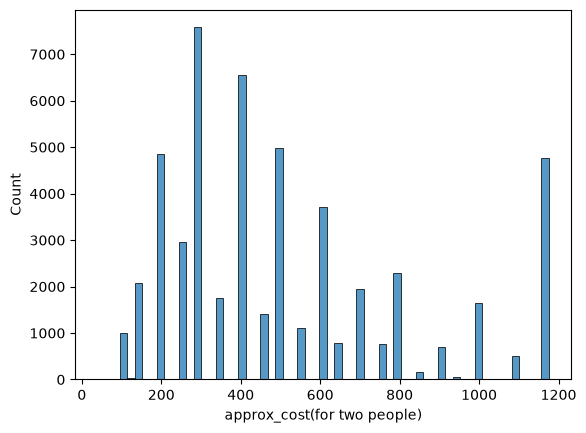

In [47]:
univar(Restaurant,'approx_cost(for two people)')

Insights = 
+ The largest concentration is around ₹300, followed by price points such as ₹400, ₹200, ₹500 and ₹600.
+ There are fewer restaurants at very high price points.

#### For Categorical column

In [48]:
for i in Restaurant.columns:
    if Restaurant[i].dtype == 'str' and Restaurant[i].nunique() <15:
        print(i)

online_order
book_table
listed_in(type)
price_category
rating_category
engagement_category
performance_group


In [49]:
def unicat(f,v):
    sns.histplot(data=f,x=v)
    plt.xticks(rotation = 45)

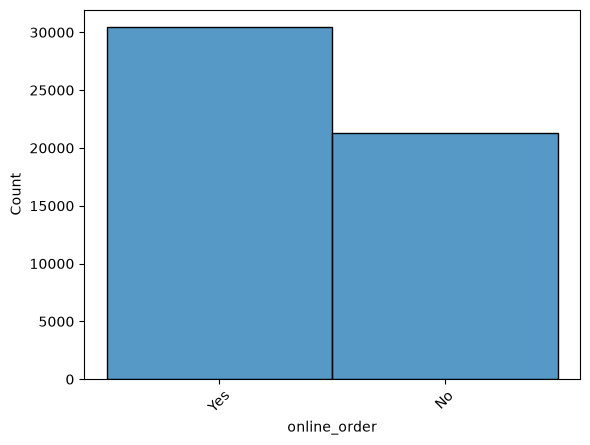

In [50]:
unicat(Restaurant,'online_order')

Insights = 
+ Yes = approximately 30,000+ restaurants
+ No = approximately 21,000+ restaurants

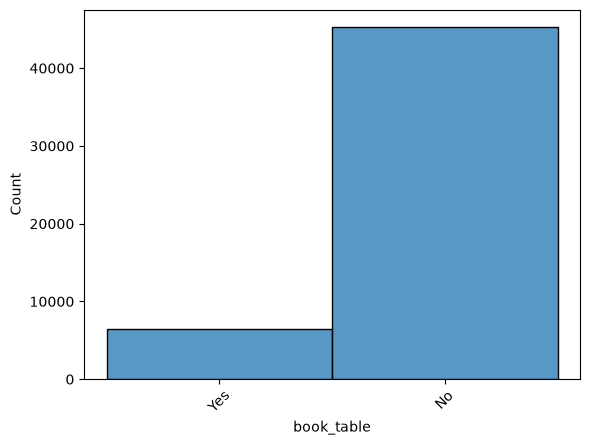

In [51]:
unicat(Restaurant,'book_table')

Insights = 
+ No: approximately 45,000+
+ Yes: approximately 6,000+

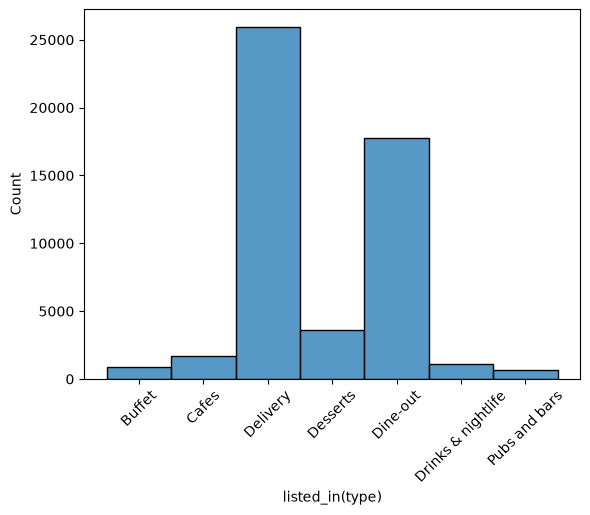

In [52]:
unicat(Restaurant,'listed_in(type)')

Insights = 
+ Delivery has the largest number of restaurants, followed by Dine-out
+ There is a large gap between these two categories and the remaining restaurant types.

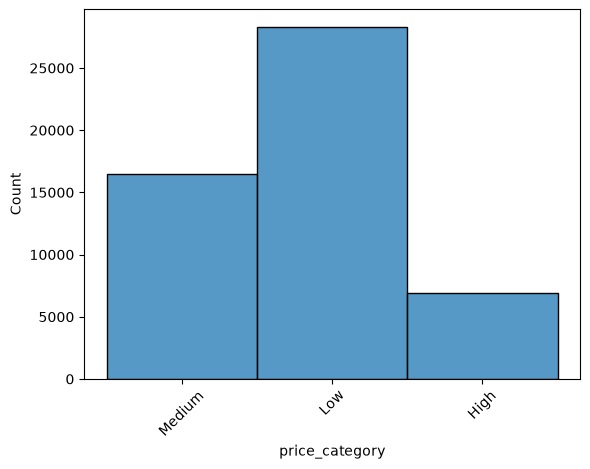

In [53]:
unicat(Restaurant,'price_category')

Insights = 
+ Low-priced restaurants are the largest group.
+ Medium-priced restaurants are the second-largest group.
+ High-priced restaurants form the smallest segment.

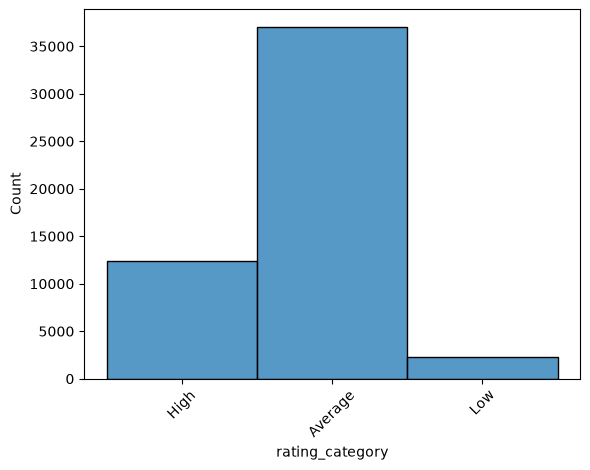

In [54]:
unicat(Restaurant,'rating_category')

Insights = 
+ Most restaurants fall into the Average rating category.
+ High-rated restaurants form a smaller group
+ Low-rated restaurants are relatively rare.

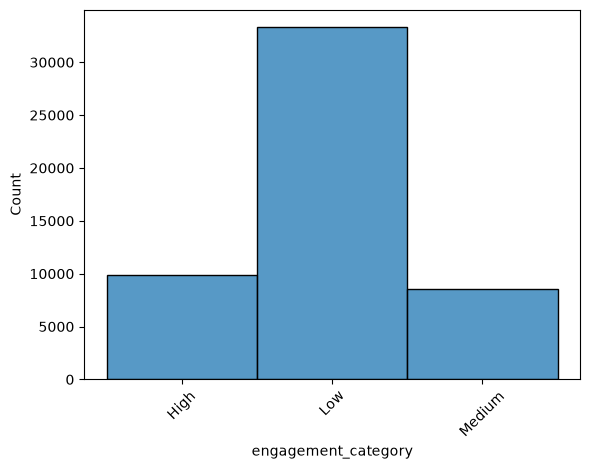

In [55]:
unicat(Restaurant,'engagement_category')

+ Most restaurants fall under Low Engagement.
+ High-engagement restaurants form the second-largest group.
+ Medium engagement is the smallest of the three categories.

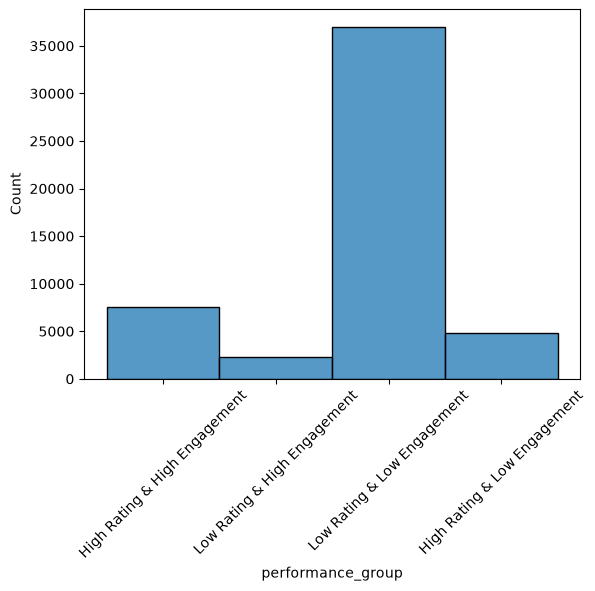

In [56]:
unicat(Restaurant,'performance_group')

Insights = 
+ Low Rating & Low Engagement are high compare to others 

In [57]:
Restaurant = Restaurant.drop('url',axis=1)
Restaurant

,address,name,online_order,book_table,rate,votes,phone,location,rest_type,dish_liked,cuisines,approx_cost(for two people),reviews_list,menu_item,listed_in(type),listed_in(city),price_category,rating_category,engagement_category,performance_group
0,"942, 21st Main Road, 2nd Stage, Banashankari, ...",Jalsa,Yes,Yes,4.100000,484.5,080 42297555\r\n+91 9743772233,Banashankari,Casual Dining,"Pasta, Lunch Buffet, Masala Papad, Paneer Laja...","North Indian, Mughlai, Chinese",800.0,"[('Rated 4.0', 'RATED\n A beautiful place to ...",[],Buffet,Banashankari,Medium,High,High,High Rating & High Engagement
1,"2nd Floor, 80 Feet Road, Near Big Bazaar, 6th ...",Spice Elephant,Yes,No,4.100000,484.5,080 41714161,Banashankari,Casual Dining,"Momos, Lunch Buffet, Chocolate Nirvana, Thai G...","Chinese, North Indian, Thai",800.0,"[('Rated 4.0', 'RATED\n Had been here for din...",[],Buffet,Banashankari,Medium,High,High,High Rating & High Engagement
2,"1112, Next to KIMS Medical College, 17th Cross...",San Churro Cafe,Yes,No,3.800000,484.5,+91 9663487993,Banashankari,"Cafe, Casual Dining","Churros, Cannelloni, Minestrone Soup, Hot Choc...","Cafe, Mexican, Italian",800.0,"[('Rated 3.0', ""RATED\n Ambience is not that ...",[],Buffet,Banashankari,Medium,Average,High,Low Rating & High Engagement
3,"1st Floor, Annakuteera, 3rd Stage, Banashankar...",Addhuri Udupi Bhojana,No,No,3.700000,88.0,+91 9620009302,Banashankari,Quick Bites,Masala Dosa,"South Indian, North Indian",300.0,"[('Rated 4.0', ""RATED\n Great food and proper...",[],Buffet,Banashankari,Low,Average,Low,Low Rating & Low Engagement
4,"10, 3rd Floor, Lakshmi Associates, Gandhi Baza...",Grand Village,No,No,3.800000,166.0,+91 8026612447\r\n+91 9901210005,Basavanagudi,Casual Dining,"Panipuri, Gol Gappe","North Indian, Rajasthani",600.0,"[('Rated 4.0', 'RATED\n Very good restaurant ...",[],Buffet,Banashankari,Medium,Average,Medium,Low Rating & Low Engagement
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
51712,"Four Points by Sheraton Bengaluru, 43/3, White...",Best Brews - Four Points by Sheraton Bengaluru...,No,No,3.600000,27.0,080 40301477,Whitefield,Bar,Biryani,Continental,1175.0,"[('Rated 5.0', ""RATED\n Food and service are ...",[],Pubs and bars,Whitefield,High,Average,Low,Low Rating & Low Engagement
51713,"Number 10, Garudachar Palya, Mahadevapura, Whi...",Vinod Bar And Restaurant,No,No,3.700449,0.0,+91 8197675843,Whitefield,Bar,Biryani,Finger Food,600.0,[],[],Pubs and bars,Whitefield,Medium,Average,Low,Low Rating & Low Engagement
51714,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Plunge - Sheraton Grand Bengaluru Whitefield H...,No,No,3.700449,0.0,080 43334321,Whitefield,Bar,Biryani,Finger Food,1175.0,[],[],Pubs and bars,Whitefield,High,Average,Low,Low Rating & Low Engagement
51715,Sheraton Grand Bengaluru Whitefield Hotel & Co...,Chime - Sheraton Grand Bengaluru Whitefield Ho...,No,Yes,4.300000,236.0,080 49652769,"ITPL Main Road, Whitefield",Bar,"Cocktails, Pizza, Buttermilk",Finger Food,1175.0,"[('Rated 4.0', 'RATED\n Nice and friendly pla...",[],Pubs and bars,Whitefield,High,High,Medium,High Rating & Low Engagement


# Business Problem

### Where the location is sutable for opening hte restaurent based on the customer preference 

for location we should cosider parameters or column like 
+ locations
+ Restaurant Count
+ Average Rating
+ Average Cost
+ Cusines
+ Performance Group


In [58]:
location_count = (Restaurant.groupby('location').size().sort_values(ascending=False))
location_count.head(10)

location
BTM                      5145
HSR                      2523
Koramangala 5th Block    2504
JP Nagar                 2235
Whitefield               2144
Indiranagar              2083
Jayanagar                1926
Marathahalli             1846
Bannerghatta Road        1630
Bellandur                1286
dtype: int64

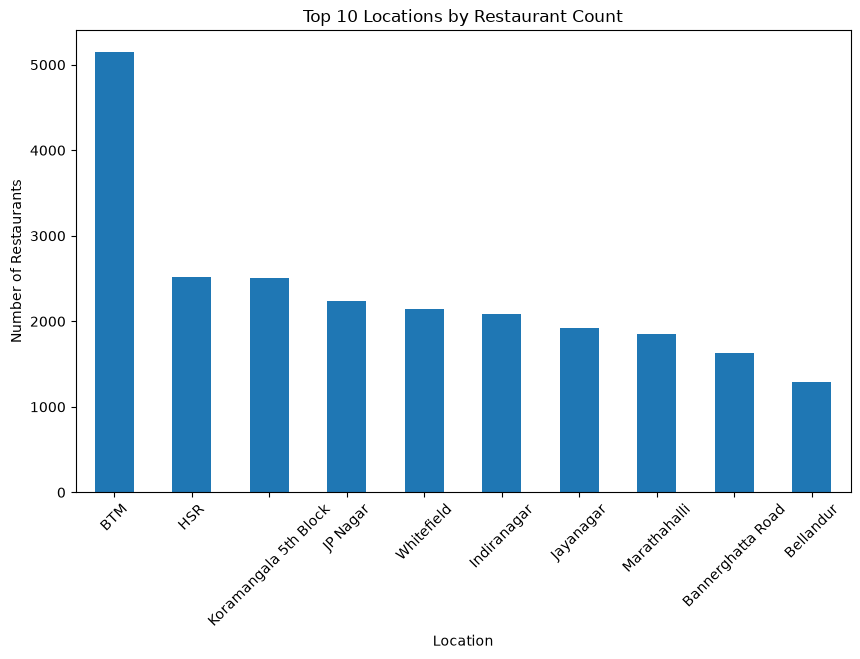

In [59]:
plt.figure(figsize=(10,6))
location_count.head(10).plot(kind='bar')
plt.title('Top 10 Locations by Restaurant Count')
plt.xlabel('Location')
plt.ylabel('Number of Restaurants')
plt.xticks(rotation=45)
plt.show()

Insights =
+ BTM has the highest number of restaurants, with about 5000+ restaurants.
+ HSR follows with about 2000+ restaurents

### rating

In [60]:
location_rating = (Restaurant.groupby('location')['rate'].mean().sort_values(ascending=False))
location_rating.head(10)

location
Lavelle Road             4.104383
St. Marks Road           4.006830
Church Street            3.988243
Koramangala 3rd Block    3.983385
Koramangala 5th Block    3.972437
Sankey Road              3.955572
Koramangala 4th Block    3.886902
Cunningham Road          3.882907
Residency Road           3.854121
MG Road                  3.852340
Name: rate, dtype: float64

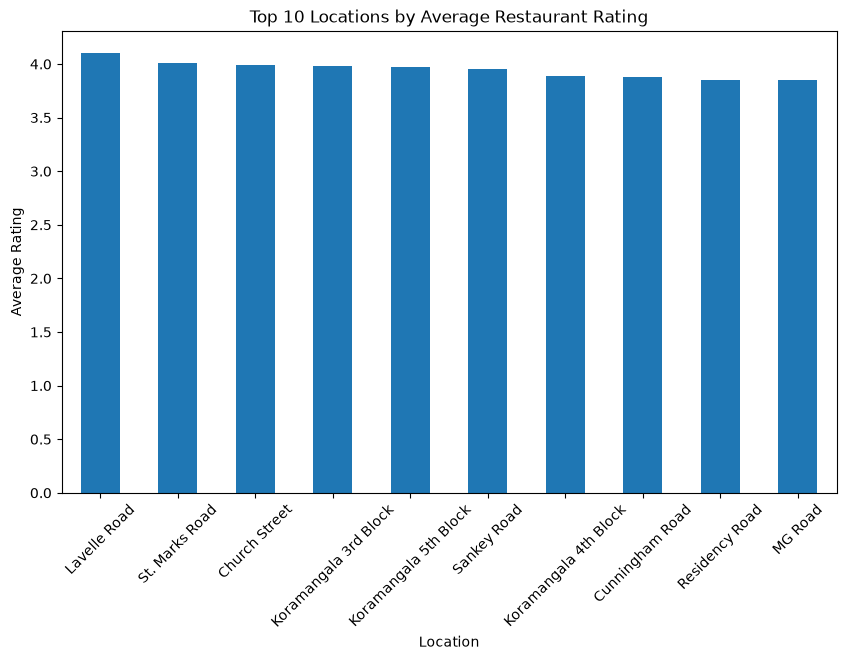

In [61]:
plt.figure(figsize=(10,6))
location_rating.head(10).plot(kind='bar')
plt.title('Top 10 Locations by Average Restaurant Rating')
plt.xlabel('Location')
plt.ylabel('Average Rating')
plt.xticks(rotation=45)
plt.show()

insights = 
+ Lavelle Road has the highest average restaurant rating among the locations shown
+ followed by St. Marks Road and Church Street and  Koramangala 3rd Block

# average cost by location 

In [62]:
location_cost = (Restaurant.groupby('location')['approx_cost(for two people)'].mean().sort_values(ascending=False))
location_cost.head(10)

location
Sankey Road             1107.407407
Lavelle Road             956.158014
Race Course Road         941.726619
Langford Town            883.333333
Infantry Road            880.960265
MG Road                  802.701915
Church Street            787.302285
Cunningham Road          775.000000
St. Marks Road           737.500000
Rajarajeshwari Nagar     725.000000
Name: approx_cost(for two people), dtype: float64

In [63]:
location_analysis = (Restaurant.groupby("location").agg(restaurant_count=("name", "count"),
          avg_rating=("rate", "mean"),
          avg_cost=("approx_cost(for two people)", "mean"),
          avg_votes=("votes", "mean")).sort_values("restaurant_count", ascending=False).head(15))

In [64]:
location_analysis

,restaurant_count,avg_rating,avg_cost,avg_votes
location,,,,
BTM,5145,3.609280,395.867888,78.778134
HSR,2523,3.683562,471.159918,127.876140
Koramangala 5th Block,2504,3.972437,623.811871,247.413738
JP Nagar,2235,3.689097,512.833180,130.231320
Whitefield,2144,3.645407,541.007345,109.454058
Indiranagar,2083,3.821222,606.752002,215.192751
Jayanagar,1926,3.770107,470.090058,151.187175
Marathahalli,1846,3.591376,488.105274,106.800921
Bannerghatta Road,1630,3.566121,442.577062,84.638037


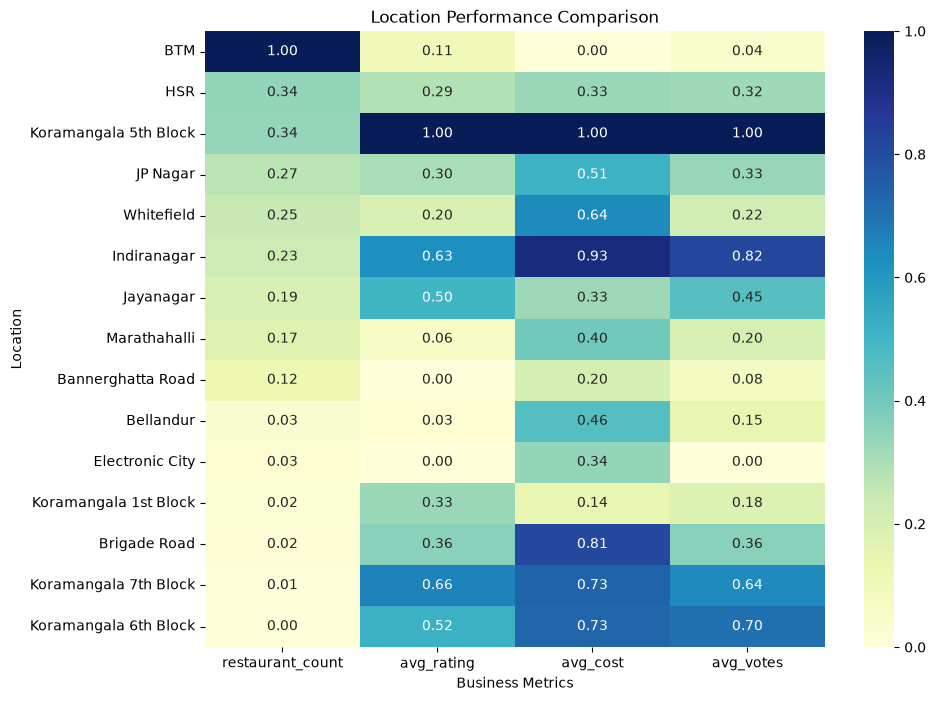

In [65]:
import seaborn as sns
import matplotlib.pyplot as plt
heatmap_data = location_analysis[
    ["restaurant_count", "avg_rating", "avg_cost", "avg_votes"]
]

# Normalizing each column to 0–1
heatmap_data = (heatmap_data - heatmap_data.min()) / (heatmap_data.max() - heatmap_data.min())
plt.figure(figsize=(10, 8))
sns.heatmap(heatmap_data,annot=True,cmap="YlGnBu",fmt=".2f")
plt.title("Location Performance Comparison")
plt.xlabel("Business Metrics")
plt.ylabel("Location")
plt.show()

# insigths and business decision 

As by the given data if we want to open restaurent then the location should have considers some parameters like :
+ Less restaurents
+ High ratings
+ cost should be reasonable
+ and costemers votes should be high

By considering all this we go with heatmap as by the heatmap we can plot num and Num columns as our data manuplated or their in the Numerical values only 

So for that we want **Normalized** values like for :
+ Restaurents we want (between 0 to 0.5 for low compition like moderate relation)
+ ratings (0.7 to 1 for better rating)
+ cost (0 to 0.6 for reasonable cost)
+ votes (0.7 to 1)

for all this there is some lacation that is sutable for above conditions 
- **Koramnagala 5th Block having:**
- 0.3 (Restaurent count 'low compition')
- 1.0 (Average rating 'good ratings compare to others')
- 1.0 (As the cost is high aprrox (for two))
- 1.0 (positive votes are high compare to other)
  
+  **Idhiranagr**
+ 0.2 (Restaurent count 'low compition' compare to Koramnagala 5th block )
+ 0.63 (Average rating 'moderate ratings compare to others' low aratings compare to Koramnagala 5th block)
+ 0.9 (As the cost is high aprrox (for two) aprrox same as the Koramnagala 5th block)
+ 0.8 (votes are good)
  
- **Koramangala 7th bloack**
- 0.01 (Restaurent count 'dead low compition' compare to other two )
- 0.66 (Average rating are good as idiranagar)
- 0.73 (As the cost is low, aprrox (for two) compare to others)
- 0.64 (costemer votes are neither good nor bad)


# DECISION 2 — WHAT TYPE?

for this we want 
+ Restaurant Type
+ Restaurant Count
+ Average Rating
+ Average Votes
+ Average Cost

### restaurent type count

In [66]:
type_count = (
    Restaurant.groupby('rest_type')
    .size()
    .sort_values(ascending=False)
)
type_count

rest_type
Quick Bites                   19359
Casual Dining                 10330
Cafe                           3732
Delivery                       2604
Dessert Parlor                 2263
                              ...  
Dessert Parlor, Kiosk             2
Food Court, Beverage Shop         2
Pop Up                            2
Quick Bites, Kiosk                1
Sweet Shop, Dessert Parlor        1
Length: 93, dtype: int64

## average ratin 

In [67]:
type_rating = (
    Restaurant.groupby('rest_type')['rate']
    .mean()
    .sort_values(ascending=False)
)
type_rating

rest_type
Bar, Pub                      4.500000
Pub, Cafe                     4.497500
Microbrewery, Bar             4.446154
Casual Dining, Irani Cafee    4.406667
Cafe, Lounge                  4.400000
                                ...   
Food Court, Casual Dining     3.300000
Quick Bites, Kiosk            3.300000
Bhojanalya                    3.266667
Bakery, Food Court            3.100000
Dessert Parlor, Kiosk         3.000000
Name: rate, Length: 93, dtype: float64

### average votes

In [68]:
type_votes = (
    Restaurant.groupby('rest_type')['votes']
    .mean()
    .sort_values(ascending=False)
)

type_votes

rest_type
Bar, Pub                      484.5
Bar, Quick Bites              484.5
Fine Dining, Microbrewery     484.5
Fine Dining, Lounge           484.5
Pub, Cafe                     484.5
                              ...  
Bakery, Kiosk                   0.0
Bakery, Sweet Shop              0.0
Mess, Quick Bites               0.0
Pop Up                          0.0
Sweet Shop, Dessert Parlor      0.0
Name: votes, Length: 93, dtype: float64

### average cost 

In [69]:
type_cost = (
    Restaurant.groupby('rest_type')['approx_cost(for two people)']
    .mean()
    .sort_values(ascending=False)
)

type_cost.head(10)

rest_type
Bar, Lounge                    1175.0
Cafe, Bar                      1175.0
Bar, Quick Bites               1175.0
Microbrewery, Lounge           1175.0
Microbrewery, Casual Dining    1175.0
Pub, Cafe                      1175.0
Lounge, Casual Dining          1175.0
Fine Dining, Bar               1175.0
Fine Dining, Microbrewery      1175.0
Fine Dining, Lounge            1175.0
Name: approx_cost(for two people), dtype: float64

### all combined 

In [70]:
type_summary = (
    Restaurant.groupby('rest_type')
    .agg(
        restaurant_count=('name', 'count'),
        average_rating=('rate', 'mean'),
        average_votes=('votes', 'mean'),
        average_cost=('approx_cost(for two people)', 'mean')
    )
    .sort_values('restaurant_count', ascending=False)
    .head(10)
)
type_summary

,restaurant_count,average_rating,average_votes,average_cost
rest_type,,,,
Quick Bites,19359,3.591077,64.610569,319.853359
Casual Dining,10330,3.749777,219.989690,748.058929
Cafe,3732,3.840366,186.150054,612.297540
Delivery,2604,3.622625,70.553187,433.833079
Dessert Parlor,2263,3.838966,105.119090,333.953941
"Takeaway, Delivery",2037,3.587646,42.142612,391.455603
"Casual Dining, Bar",1154,4.054870,327.250000,1064.057858
Bakery,1141,3.643555,29.167397,370.315513
Beverage Shop,867,3.647521,34.057670,220.968858


In [71]:
type_heatmap = (type_summary - type_summary.min()) / (type_summary.max() - type_summary.min())

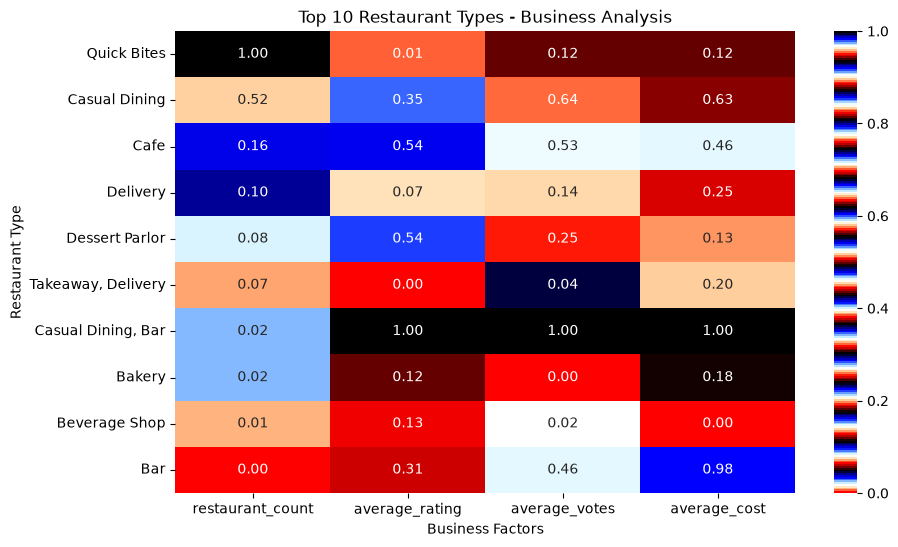

In [72]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    type_heatmap,
    annot=True,
    fmt=".2f",
    cmap="flag"
)

plt.title("Top 10 Restaurant Types - Business Analysis")
plt.xlabel("Business Factors")
plt.ylabel("Restaurant Type")

plt.show()

Insigts = 
+ Quick Bites is by far the most common restaurant type, followed by Casual Dining. Cafe, Delivery and Dessert Parlor have substantially fewer restaurants. This indicates that Quick Bites and Casual Dining are highly represented restaurant formats in the dataset.

# what cusins

In [73]:
cuisine_summary = (
    Restaurant_cuisine
    .groupby('cuisine')
    .agg(
        restaurant_count=('name', 'count'),
        average_rating=('rate', 'mean'),
        average_votes=('votes', 'mean')
    )
    .sort_values(
        'restaurant_count',
        ascending=False
    ).head(10)
)

In [74]:
cuisine_summary

,restaurant_count,average_rating,average_votes
cuisine,,,
North Indian,21130,3.658432,142.244699
Chinese,15547,3.636248,141.928121
South Indian,8644,3.636408,85.885643
Fast Food,8096,3.638819,89.901680
Biryani,6492,3.594245,121.830715
Continental,5765,3.937491,259.952732
Desserts,5633,3.826982,122.581307
Cafe,5303,3.883729,205.363002
Beverages,4747,3.787591,125.443543


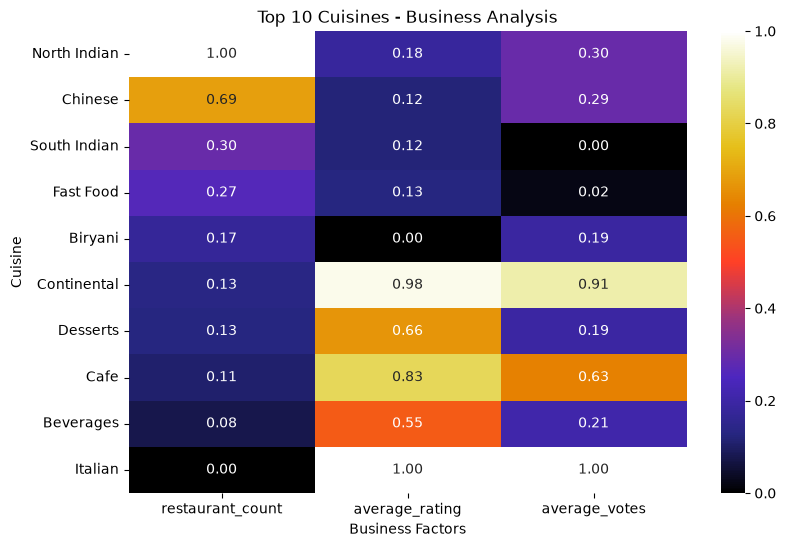

In [75]:
cuisine_heatmap = (
    cuisine_summary - cuisine_summary.min()) / (cuisine_summary.max() - cuisine_summary.min())

plt.figure(figsize=(9, 6))

sns.heatmap(
    cuisine_heatmap,
    annot=True,
    fmt=".2f",
    cmap="CMRmap"
)

plt.title("Top 10 Cuisines - Business Analysis")
plt.xlabel("Business Factors")
plt.ylabel("Cuisine")

plt.show()

insights = 
+ North Indian cuisine has the largest restaurant presence, followed by Chinese cuisine. However, cuisines with lower restaurant counts such as Italian and Continental show higher average ratings and customer engagement. Italian has an average rating of about 3.94 and the highest average votes among the listed cuisines, while Continental also has high ratings and customer engagement.

# `from this leave it project is end `

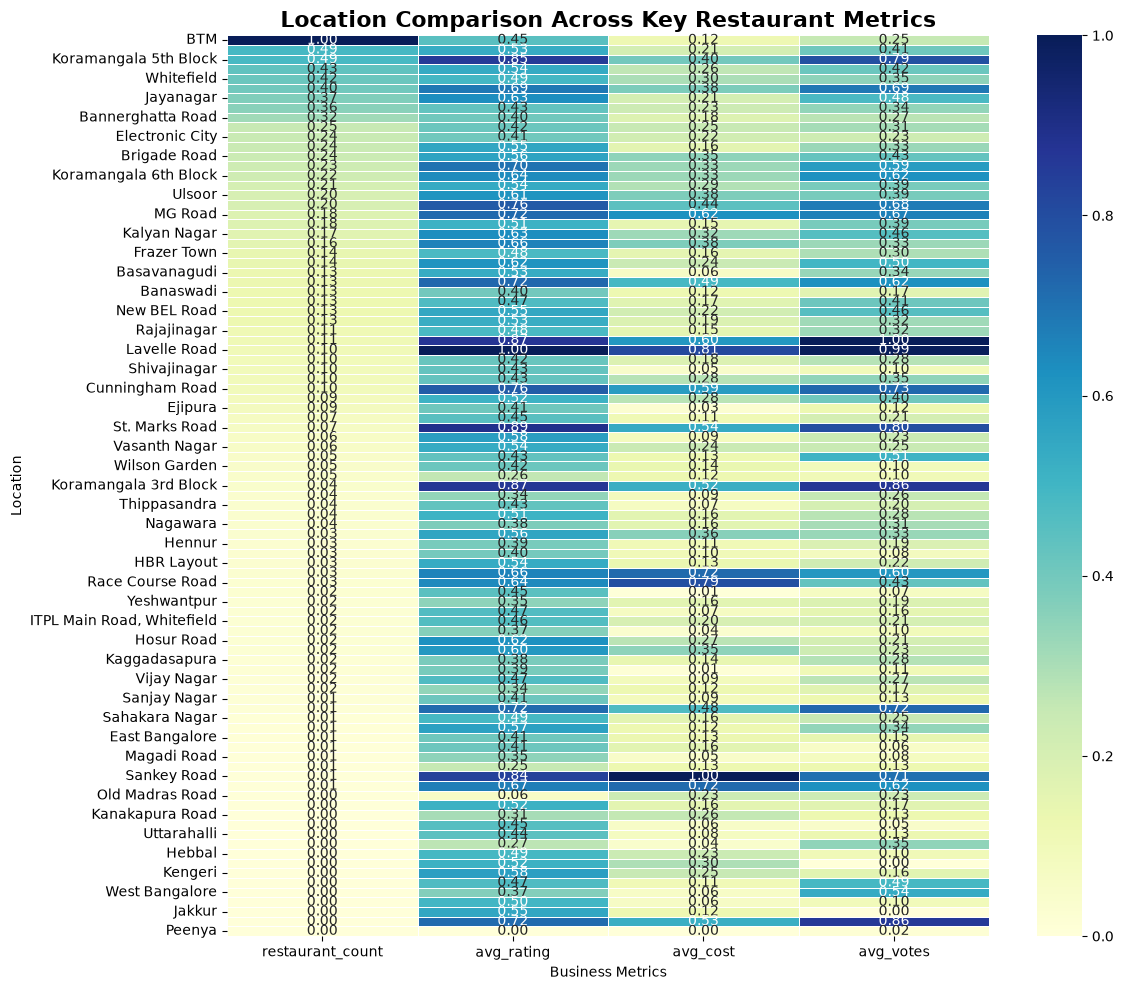

In [76]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

location_summary = (
    Restaurant.groupby('location')
    .agg(
        restaurant_count=('name', 'count'),
        avg_rating=('rate', 'mean'),
        avg_cost=('approx_cost(for two people)', 'mean'),
        avg_votes=('votes', 'mean')
    )
    .sort_values('restaurant_count', ascending=False)
)

metrics = [
    'restaurant_count',
    'avg_rating',
    'avg_cost',
    'avg_votes'
]

# Min-Max normalization
location_normalized = location_summary[metrics].copy()

location_normalized = (
    location_normalized - location_normalized.min()
) / (
    location_normalized.max() - location_normalized.min()
)

plt.figure(figsize=(12, 10))

sns.heatmap(
    location_normalized,
    annot=True,
    fmt='.2f',
    cmap='YlGnBu',
    linewidths=0.5,
    vmin=0,
    vmax=1
)

plt.title(
    'Location Comparison Across Key Restaurant Metrics',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Business Metrics')
plt.ylabel('Location')

plt.tight_layout()
plt.show()

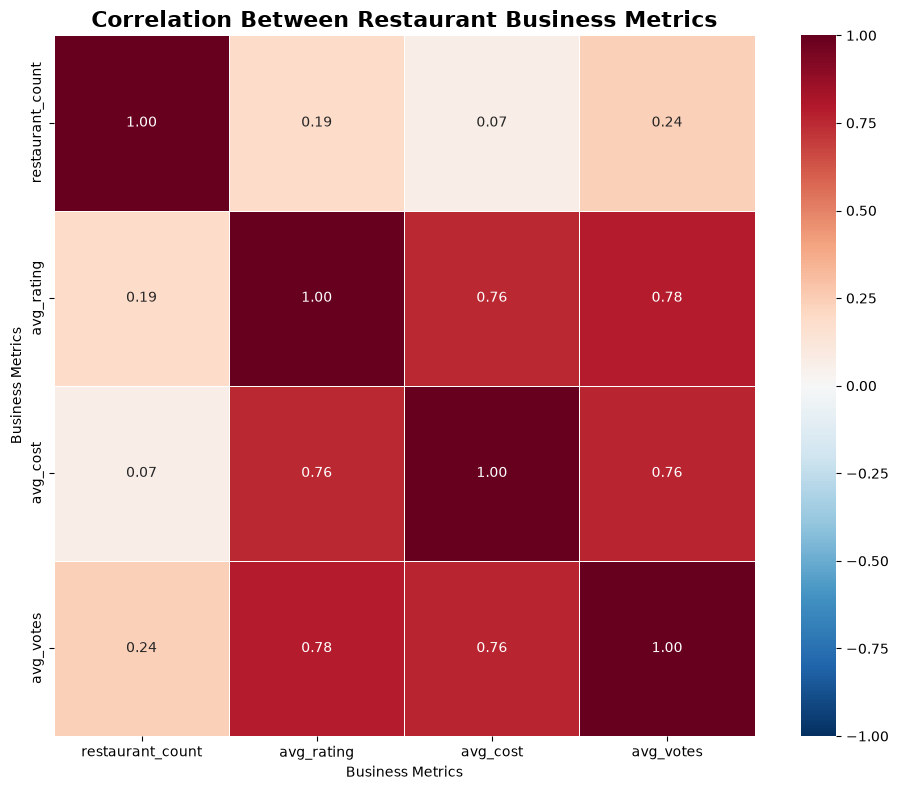

In [77]:
correlation = location_summary[metrics].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True
)

plt.title(
    'Correlation Between Restaurant Business Metrics',
    fontsize=16,
    fontweight='bold'
)

plt.xlabel('Business Metrics')
plt.ylabel('Business Metrics')

plt.tight_layout()
plt.show()